# 04 — Model training

In [1]:
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

BRANCHES = ["original", "seasonal", "trend"]
SUFFIX = {"original": "", "seasonal": "_S", "trend": "_T"}
data = {b: pd.read_csv(f"../data/processed/features_{b}.csv",
                       index_col="date", parse_dates=True) for b in BRANCHES}


def split(df):
    X = df.drop(columns=["target", "split"])
    train = df["split"] == "train"
    return X[train], X[~train], df.loc[train, "target"], df.loc[~train, "target"]


for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    print(f"{b:9s} {Xtr.shape[1]:2d} features | "
          f"train {len(Xtr)} ({Xtr.index.min():%Y-%m}..{Xtr.index.max():%Y-%m}) | "
          f"test {len(Xte)} ({Xte.index.min():%Y-%m}..{Xte.index.max():%Y-%m})")

original   8 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
seasonal   8 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)
trend      8 features | train 238 (2002-03..2021-12) | test 36 (2022-01..2024-12)


## Hyperparameter tuning

In [2]:
SEED = 0
CV = TimeSeriesSplit(n_splits=5)
N_ITER = 100

# Ranges widened after the first run, where two best values sat on an edge
# (XGBoost learning rate 0.0106 against a floor of 0.01; Ridge alpha 1e-4).
MODELS = {
    "XGBoost": (XGBRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(100, 2000), "max_depth": randint(1, 9),
        "learning_rate": loguniform(0.002, 0.3), "subsample": uniform(0.5, 0.5),
        "colsample_bytree": uniform(0.5, 0.5), "min_child_weight": randint(1, 21),
        "reg_lambda": loguniform(0.1, 100)}),
    "RandomForest": (RandomForestRegressor(random_state=SEED, n_jobs=1), {
        "n_estimators": randint(200, 1000), "max_depth": [None, 2, 3, 4, 6, 8, 12, 16],
        "min_samples_leaf": randint(1, 21), "max_features": ["sqrt", 0.33, 0.5, 0.75, 1.0]}),
    "Ridge": (make_pipeline(StandardScaler(), Ridge()), {
        "ridge__alpha": np.logspace(-6, 4, 101)}),
}


def tune(name, X, y):
    est, space = MODELS[name]
    if name == "Ridge":
        search = GridSearchCV(est, space, cv=CV,
                              scoring="neg_mean_squared_error", n_jobs=-1)
    else:
        search = RandomizedSearchCV(est, space, n_iter=N_ITER, cv=CV,
                                    scoring="neg_mean_squared_error",
                                    random_state=SEED, n_jobs=-1)
    return search.fit(X, y)


def at_edge(name, params):
    """Tuned values within 5% (log scale for rates) of the edge of their range."""
    hits = []
    for k, v in params.items():
        dist = MODELS[name][1][k]
        if isinstance(dist, list) or not isinstance(v, (int, float)):
            vals = list(dist)
            if v in (vals[0], vals[-1]) and len(vals) > 2:
                hits.append(f"{k}={v}")
            continue
        if hasattr(dist, "support"):
            lo, hi = dist.support()
        else:
            lo, hi = min(dist), max(dist)
        log = k in ("learning_rate", "reg_lambda", "ridge__alpha")
        f = (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if log else (v - lo) / (hi - lo)
        if f < 0.05 or f > 0.95:
            hits.append(f"{k}={v:.4g}")
    return hits


best_params, cv_rmse = {}, {}
for b, df in data.items():
    Xtr, _, ytr, _ = split(df)
    for name in MODELS:
        search = tune(name, Xtr, ytr)
        best_params[(b, name)] = search.best_params_
        cv_rmse[(b, name)] = np.sqrt(-search.best_score_)
        edge = at_edge(name, search.best_params_)
        print(f"{b:9s} {name:12s} CV RMSE {cv_rmse[(b, name)]:.4f}   "
              f"at an edge: {', '.join(edge) if edge else 'none'}")

original  XGBoost      CV RMSE 0.0272   at an edge: subsample=0.5192


original  RandomForest CV RMSE 0.0276   at an edge: none


original  Ridge        CV RMSE 0.0310   at an edge: none


seasonal  XGBoost      CV RMSE 0.0251   at an edge: learning_rate=0.002099


seasonal  RandomForest CV RMSE 0.0243   at an edge: min_samples_leaf=1


seasonal  Ridge        CV RMSE 0.0279   at an edge: none


trend     XGBoost      CV RMSE 0.0062   at an edge: none


trend     RandomForest CV RMSE 0.0060   at an edge: max_depth=None, max_features=1.0


trend     Ridge        CV RMSE 0.0033   at an edge: none


## Test period

In [3]:
def make_model(b, name, seed=SEED):
    est = clone(MODELS[name][0]).set_params(**best_params[(b, name)])
    if name != "Ridge":
        est.set_params(random_state=seed)
    return est


def scores(y, p):
    return dict(RMSE=np.sqrt(mean_squared_error(y, p)), R2=r2_score(y, p),
                MAE=mean_absolute_error(y, p))


def baselines(b, df, test_mask):
    y = df["target"]
    persistence = df[f"NDVI{SUFFIX[b]}_lag1"]
    clim = y[~test_mask].groupby(y[~test_mask].index.month).mean()
    climatology = pd.Series(y.index.month.map(clim), index=y.index)
    return {"persistence": persistence, "climatology": climatology}


rows, predictions = [], {}
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    test = df["split"] == "test"
    for name in MODELS:
        p = make_model(b, name).fit(Xtr, ytr).predict(Xte)
        predictions[(b, name)] = pd.Series(p, index=Xte.index)
        rows.append(dict(branch=b, model=name, **scores(yte, p)))
    for name, s in baselines(b, df, test).items():
        predictions[(b, name)] = s[test]
        rows.append(dict(branch=b, model=name, **scores(yte, s[test])))

test_scores = pd.DataFrame(rows)
ORDER = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for metric in ["RMSE", "R2", "MAE"]:
    print(f"\n{metric}")
    print(test_scores.pivot(index="model", columns="branch", values=metric)
                     .loc[ORDER, BRANCHES].round(4).to_string())


RMSE
branch        original  seasonal   trend
model                                   
XGBoost         0.0262    0.0267  0.0019
RandomForest    0.0253    0.0249  0.0014
Ridge           0.0285    0.0280  0.0015
persistence     0.0420    0.0416  0.0015
climatology     0.0263    0.0271  0.0093

R2
branch        original  seasonal   trend
model                                   
XGBoost         0.4166    0.3768  0.9383
RandomForest    0.4574    0.4586  0.9681
Ridge           0.3121    0.3165  0.9630
persistence    -0.4978   -0.5094  0.9604
climatology     0.4105    0.3585 -0.4631

MAE
branch        original  seasonal   trend
model                                   
XGBoost         0.0214    0.0224  0.0015
RandomForest    0.0203    0.0209  0.0011
Ridge           0.0227    0.0235  0.0012
persistence     0.0321    0.0321  0.0012
climatology     0.0231    0.0235  0.0086


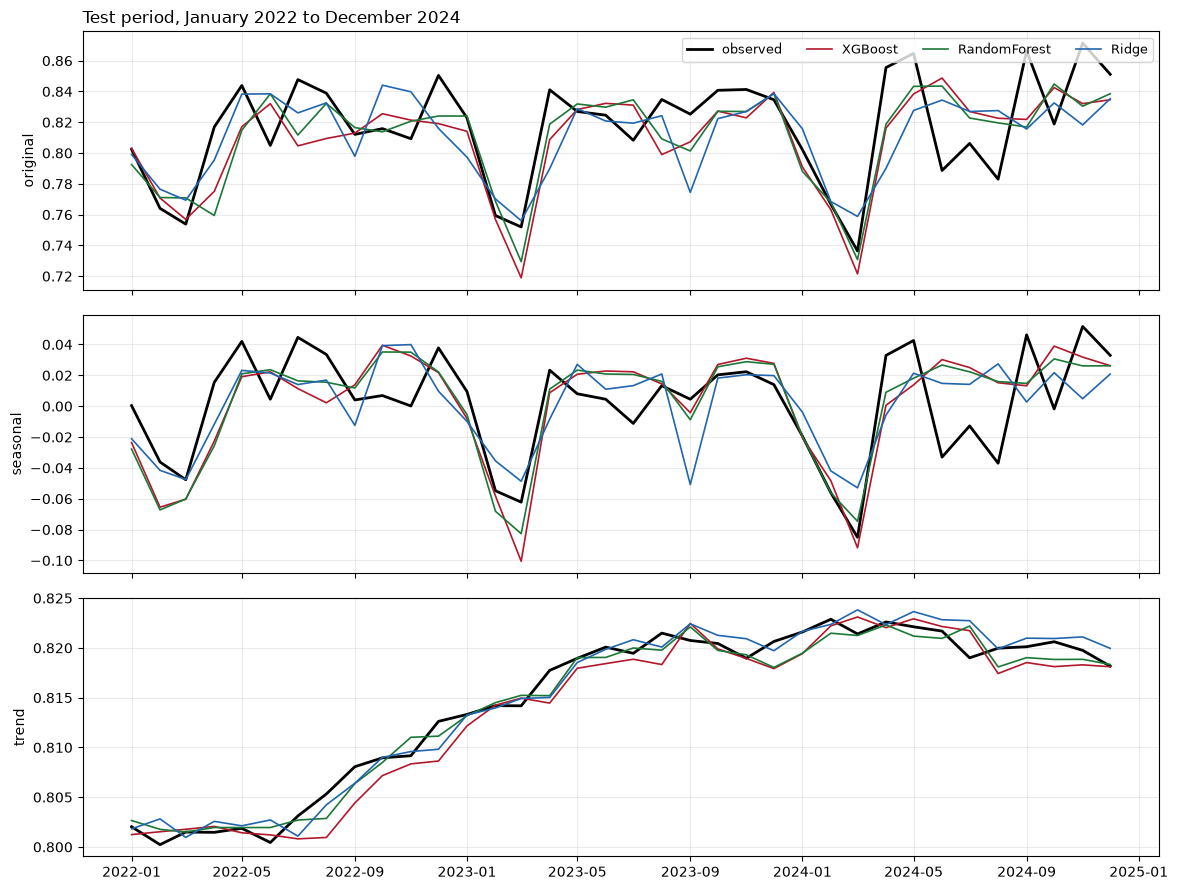

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
colors = {"XGBoost": "#b2182b", "RandomForest": "#1b7837", "Ridge": "#2166ac"}
for ax, b in zip(axes, BRANCHES):
    _, Xte, _, yte = split(data[b])
    ax.plot(yte.index, yte, color="black", lw=2, label="observed")
    for name, c in colors.items():
        ax.plot(yte.index, predictions[(b, name)], color=c, lw=1.2, label=name)
    ax.set_ylabel(b)
    ax.grid(alpha=0.25)
axes[0].legend(ncol=4, loc="upper right", fontsize=9)
axes[0].set_title("Test period, January 2022 to December 2024", loc="left")
fig.tight_layout()
fig.savefig("../figures/04_test_predictions.png", dpi=150, bbox_inches="tight")
plt.show()

## Noise floor

In [5]:
floor = []
for b, df in data.items():
    Xtr, Xte, ytr, yte = split(df)
    for name in MODELS:
        seeds = [SEED] if name == "Ridge" else range(20)
        runs = [scores(yte, make_model(b, name, s).fit(Xtr, ytr).predict(Xte)) for s in seeds]
        floor.append(dict(branch=b, model=name,
                          RMSE_mean=np.mean([r["RMSE"] for r in runs]),
                          RMSE_sd=np.std([r["RMSE"] for r in runs]),
                          R2_mean=np.mean([r["R2"] for r in runs]),
                          R2_sd=np.std([r["R2"] for r in runs])))

noise_floor = pd.DataFrame(floor)
print(noise_floor.round(4).to_string(index=False))

  branch        model  RMSE_mean  RMSE_sd  R2_mean  R2_sd
original      XGBoost     0.0262   0.0002   0.4158 0.0084
original RandomForest     0.0256   0.0002   0.4436 0.0103
original        Ridge     0.0285   0.0000   0.3121 0.0000
seasonal      XGBoost     0.0266   0.0001   0.3838 0.0054
seasonal RandomForest     0.0252   0.0002   0.4467 0.0075
seasonal        Ridge     0.0280   0.0000   0.3165 0.0000
   trend      XGBoost     0.0019   0.0001   0.9420 0.0058
   trend RandomForest     0.0014   0.0000   0.9672 0.0011
   trend        Ridge     0.0015   0.0000   0.9630 0.0000


## Rolling-origin evaluation

In [6]:
WINDOWS = [("2010-01-01", "2012-12-01"), ("2013-01-01", "2015-12-01"),
           ("2016-01-01", "2018-12-01"), ("2019-01-01", "2021-12-01"),
           ("2022-01-01", "2024-12-01")]

folds = []
for b, df in data.items():
    X, y = df.drop(columns=["target", "split"]), df["target"]
    for start, end in WINDOWS:
        tr, te = df.index < start, (df.index >= start) & (df.index <= end)
        for name in MODELS:
            p = make_model(b, name).fit(X[tr], y[tr]).predict(X[te])
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], p)),
                              R2=r2_score(y[te], p)))
        for name, s in baselines(b, df, ~tr).items():
            folds.append(dict(branch=b, window=start[:4] + "-" + end[2:4], model=name,
                              RMSE=np.sqrt(mean_squared_error(y[te], s[te])),
                              R2=r2_score(y[te], s[te])))

rolling = pd.DataFrame(folds)
order = ["XGBoost", "RandomForest", "Ridge", "persistence", "climatology"]
for b in BRANCHES:
    for metric, digits in [("RMSE", 4), ("R2", 3)]:
        t = rolling[rolling.branch == b].pivot(index="model", columns="window",
                                               values=metric).loc[order]
        t["mean"], t["sd"] = t.mean(axis=1), t.std(axis=1)
        print(f"\n{b} — {metric}"); print(t.round(digits).to_string())


original — RMSE
window        2010-12  2013-15  2016-18  2019-21  2022-24    mean      sd
model                                                                    
XGBoost        0.0250   0.0241   0.0185   0.0402   0.0262  0.0268  0.0081
RandomForest   0.0259   0.0233   0.0187   0.0409   0.0253  0.0268  0.0084
Ridge          0.0298   0.0227   0.0229   0.0448   0.0285  0.0297  0.0090
persistence    0.0481   0.0359   0.0339   0.0583   0.0420  0.0436  0.0099
climatology    0.0303   0.0233   0.0197   0.0439   0.0263  0.0287  0.0093

original — R2
window        2010-12  2013-15  2016-18  2019-21  2022-24   mean     sd
model                                                                  
XGBoost         0.763    0.521    0.763    0.426    0.417  0.578  0.174
RandomForest    0.746    0.554    0.758    0.407    0.457  0.584  0.162
Ridge           0.663    0.575    0.638    0.290    0.312  0.495  0.181
persistence     0.121   -0.065    0.207   -0.206   -0.498 -0.088  0.280
climatology     0.

## Reconstruction

In [7]:
y_orig = split(data["original"])[3]
recon = []
for name in MODELS:
    p = (predictions[("seasonal", name)] + predictions[("trend", name)]).reindex(y_orig.index)
    direct = test_scores.query("branch == 'original' and model == @name").iloc[0]
    recon.append(dict(model=name,
                      RMSE_direct=direct.RMSE, RMSE_reconstructed=np.sqrt(mean_squared_error(y_orig, p)),
                      R2_direct=direct.R2, R2_reconstructed=r2_score(y_orig, p)))
print(pd.DataFrame(recon).round(4).to_string(index=False))

       model  RMSE_direct  RMSE_reconstructed  R2_direct  R2_reconstructed
     XGBoost       0.0262              0.0268     0.4166            0.3887
RandomForest       0.0253              0.0250     0.4574            0.4703
       Ridge       0.0285              0.0283     0.3121            0.3181


## Saving

In [8]:
json.dump({f"{b}|{m}": {k: (v.item() if hasattr(v, "item") else v) for k, v in p.items()}
           for (b, m), p in best_params.items()},
          open("../results/04_best_params.json", "w"), indent=2)
test_scores.to_csv("../results/04_test_scores.csv", index=False)
noise_floor.to_csv("../results/04_noise_floor.csv", index=False)
rolling.to_csv("../results/04_rolling_origin.csv", index=False)
pd.DataFrame({f"{b}|{m}": s for (b, m), s in predictions.items()}) \
  .to_csv("../results/04_test_predictions.csv")
print("saved")

saved
